# 01 — Tiền xử lý dữ liệu (Data Cleaning)

**Người phụ trách:** Thành viên 1 (Khoa) · **Phiên bản dữ liệu đầu ra:** `cleaned_cars.csv` **v1.0**

**Dữ liệu gốc:** `Car details v3.csv` trong bộ *Vehicle dataset from CarDekho*
(https://www.kaggle.com/datasets/nehalbirla/vehicle-dataset-from-cardekho), 8.128 dòng × 13 cột.

Notebook này tự chứa: chạy được bằng **Restart & Run All** trên Kaggle (thêm dataset trên làm Input)
hoặc trong repository (đọc `data/raw/`). Mọi con số trong Chương 2 (mục 2.7) và trong
`docs/nhat_ky_lam_sach.md` đều lấy từ các ô code bên dưới.

**Thứ tự xử lý (đã thống nhất trong bảng phân công):**

| Bước | Nội dung |
|---|---|
| 0 | Đọc dữ liệu gốc, kiểm tra cấu trúc |
| 1 | Đếm và xoá dòng trùng lặp hoàn toàn (**trước mọi bước khác**) |
| 2 | Tách đơn vị `mileage`, `engine`, `max_power` về dạng số; tách `torque` về Nm |
| 3 | Loại dòng khuyết ở các biến kỹ thuật chính (gồm giá trị vô nghĩa như `mileage = 0`) |
| 4 | Xử lý mức hiếm: loại `Test Drive Car`, gộp `Trustmark Dealer` vào `Dealer` |
| 5 | Loại giá trị vô lý của `km_driven` (không cắt ngoại lai giá theo IQR) |
| 6 | Tạo biến mới: `brand`, `model`, `car_age`, `log_price`, `fuel_group`, `owner_rank` |
| 7 | Kiểm tra cuối, xuất `cleaned_cars.csv` v1.0 và nhật ký làm sạch |

In [1]:
import hashlib
import json
import re
from datetime import date
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# ---- Quy ước chung của nhóm ----
ALPHA = 0.05
RANDOM_STATE = 42
REFERENCE_YEAR = 2020          # năm thu thập dữ liệu -> car_age = 2020 - year
KM_MAX = 500_000               # km_driven > 500.000 bị coi là vô lý
KM_MIN = 1_000                 # km_driven < 1.000 với xe >= 2 năm tuổi bị coi là vô lý
MIN_AGE_FOR_KM_MIN = 2
KGM_TO_NM = 9.80665            # 1 kgf·m = 9,80665 N·m
KGM_MAX = 60                   # > 60 kgf·m (~590 N·m) với xe con là vô lý -> số thực chất là N·m bị ghi nhầm đơn vị
TORQUE_MAX_NM = 700            # > 700 N·m là vô lý (lớn nhất hợp lệ: Volvo XC90 T8 640 N·m) -> NA
DATA_VERSION = "1.0"
FREEZE_DATE = "2026-11-18"

# ---- Quy chuẩn hình (300 dpi, nhãn tiếng Việt) ----
matplotlib.rcParams.update({
    "font.family": "DejaVu Sans",   # có đủ dấu tiếng Việt
    "figure.dpi": 100,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

# ---- Đường dẫn: tự nhận Kaggle hoặc repository ----
RAW_NAME = "Car details v3.csv"
on_kaggle = Path("/kaggle/input").exists()
if on_kaggle:
    hits = sorted(Path("/kaggle/input").rglob(RAW_NAME))
    if not hits:
        raise FileNotFoundError("Hãy Add Input dataset 'nehalbirla/vehicle-dataset-from-cardekho'")
    RAW_PATH = hits[0]
    OUT_DIR = Path("/kaggle/working")
    FIG_DIR = OUT_DIR / "figures"
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw" / RAW_NAME).exists())
    RAW_PATH = ROOT / "data" / "raw" / RAW_NAME
    OUT_DIR = ROOT / "data" / "processed"
    FIG_DIR = ROOT / "figures" / "01_cleaning"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)


def sha256(path: Path) -> str:
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()


print("Môi trường :", "Kaggle" if on_kaggle else "Repository")
print("File gốc   :", RAW_PATH)
print("SHA-256    :", sha256(RAW_PATH))

Môi trường : Repository
File gốc   : /home/user/XSTK/data/raw/Car details v3.csv
SHA-256    : 788e7f7a5be161011789a0d4b64ea0879570348c943a414f4f99953f58d74048


## Bước 0 — Đọc dữ liệu gốc

File gốc **không được sửa**. Ta giữ lại chỉ số dòng gốc (`raw_index`, đếm từ 0 theo thứ tự
dòng dữ liệu trong file, không tính dòng tiêu đề) để truy vết mọi dòng của file sạch về file gốc.

In [2]:
raw = pd.read_csv(RAW_PATH)
raw.index.name = "raw_index"
print("Kích thước:", raw.shape)
display(raw.head())
raw.info()

Kích thước: (8128, 13)


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
raw_index,,,,,,,,,,,,,
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB


In [3]:
# Nhật ký: số dòng còn lại sau mỗi bước
log = []


def log_step(step, description, before, after, reason):
    log.append({"buoc": step, "noi_dung": description, "so_dong_truoc": before,
                "so_dong_bi_loai": before - after, "so_dong_con_lai": after, "ly_do": reason})
    print(f"[Bước {step}] {description}: {before:,} -> {after:,} (loại {before - after:,})")


EXPECTED_COLS = ["name", "year", "selling_price", "km_driven", "fuel", "seller_type", "transmission",
                 "owner", "mileage", "engine", "max_power", "torque", "seats"]
assert list(raw.columns) == EXPECTED_COLS, "Cấu trúc cột khác với Car details v3.csv"
log_step(0, "Đọc dữ liệu gốc", len(raw), len(raw), "Car details v3.csv, 13 cột")

# Giá trị khuyết trong dữ liệu gốc
na_raw = pd.DataFrame({"so_NA": raw.isna().sum(), "ty_le_%": (raw.isna().mean() * 100).round(2)})
na_raw

[Bước 0] Đọc dữ liệu gốc: 8,128 -> 8,128 (loại 0)


,so_NA,ty_le_%
name,0,0.00
year,0,0.00
selling_price,0,0.00
km_driven,0,0.00
fuel,0,0.00
seller_type,0,0.00
transmission,0,0.00
owner,0,0.00
mileage,221,2.72
engine,221,2.72


## Bước 1 — Dòng trùng lặp

Một dòng bị coi là trùng khi **cả 13 cột** giống hệt một dòng khác (tin rao bị đăng lại).
Giữ lại lần xuất hiện đầu tiên. Bước này làm **trước mọi bước khác** để các bước sau
(đếm mức hiếm, đếm NA) phản ánh đúng số xe thực.

In [4]:
dup_mask = raw.duplicated(keep="first")
n_dup = int(dup_mask.sum())
n_dup_groups = int(raw[raw.duplicated(keep=False)].groupby(EXPECTED_COLS, dropna=False).ngroups)
print(f"Số dòng trùng (bị xoá): {n_dup:,}  — thuộc {n_dup_groups:,} nhóm dòng giống nhau")

df = raw.loc[~dup_mask].copy()
log_step(1, "Xoá dòng trùng lặp hoàn toàn", len(raw), len(df), "Trùng cả 13 cột, giữ lần xuất hiện đầu")

# Ảnh hưởng của việc xoá trùng tới các mức hiếm
compare = pd.DataFrame({
    "truoc_xoa_trung": raw["seller_type"].value_counts(),
    "sau_xoa_trung": df["seller_type"].value_counts(),
})
compare

Số dòng trùng (bị xoá): 1,202  — thuộc 625 nhóm dòng giống nhau
[Bước 1] Xoá dòng trùng lặp hoàn toàn: 8,128 -> 6,926 (loại 1,202)


,truoc_xoa_trung,sau_xoa_trung
seller_type,,
Individual,6766,6218
Dealer,1126,681
Trustmark Dealer,236,27


## Bước 2 — Tách đơn vị về dạng số

| Cột gốc | Dạng gốc | Cột mới | Ghi chú |
|---|---|---|---|
| `mileage` | `23.4 kmpl`, `26.6 km/kg` | `mileage` (số), `mileage_unit` | **2 đơn vị khác nhau**, không so sánh chung |
| `engine` | `1248 CC` | `engine` (cc) | |
| `max_power` | `74 bhp`; có ô `0` hoặc chỉ ` bhp` | `max_power` (bhp) | ô không có số → NA |
| `torque` | `190Nm@ 2000rpm`, `12.7@ 2,700(kgm@ rpm)`… | `torque_nm` (N·m) | kgm × 9,80665 |
| `seats` | số thực `5.0` | `seats` (số nguyên) | |

In [5]:
def split_number_unit(s: pd.Series):
    """Tách '23.4 kmpl' -> (23.4, 'kmpl'). Ô không có số -> NaN."""
    s = s.astype("string").str.strip()
    num = pd.to_numeric(s.str.extract(r"^([0-9]*\.?[0-9]+)", expand=False), errors="coerce")
    unit = s.str.extract(r"([A-Za-z/]+)\s*$", expand=False)
    return num, unit


mileage_num, mileage_unit = split_number_unit(df["mileage"])
engine_num, engine_unit = split_number_unit(df["engine"])
power_num, power_unit = split_number_unit(df["max_power"])

print("Đơn vị mileage  :", mileage_unit.value_counts(dropna=False).to_dict())
print("Đơn vị engine   :", engine_unit.value_counts(dropna=False).to_dict())
print("Đơn vị max_power:", power_unit.value_counts(dropna=False).to_dict())

# Ô max_power không có số hợp lệ (ví dụ '0' hoặc ' bhp')
bad_power = df["max_power"].notna() & (power_num.isna() | (power_num <= 0))
print("\nmax_power không có giá trị hợp lệ:", int(bad_power.sum()))
display(df.loc[bad_power, ["name", "mileage", "engine", "max_power", "torque"]])

Đơn vị mileage  : {'kmpl': 6631, <NA>: 208, 'km/kg': 87}
Đơn vị engine   : {'CC': 6718, <NA>: 208}
Đơn vị max_power: {'bhp': 6718, <NA>: 208}

max_power không có giá trị hợp lệ: 4


,name,mileage,engine,max_power,torque
raw_index,,,,,
575,Maruti Alto K10 LXI,NaN,NaN,0,NaN
1442,Maruti Swift Dzire VDI Optional,NaN,NaN,0,NaN
2549,Tata Indica Vista Quadrajet LS,NaN,NaN,0,NaN
4933,Maruti Omni CNG,10.9 km/kg,796 CC,bhp,NaN


In [6]:
# Đơn vị mileage phải khớp với nhiên liệu: kmpl cho Petrol/Diesel, km/kg cho CNG/LPG
pd.crosstab(df["fuel"], mileage_unit.fillna("NA"), margins=True)

mileage,NA,km/kg,kmpl,All
fuel,,,,
CNG,4,52,0,56
Diesel,97,0,3658,3755
LPG,3,35,0,38
Petrol,104,0,2973,3077
All,208,87,6631,6926


**Kết luận về `mileage`:** đơn vị khớp hoàn toàn với nhiên liệu — `kmpl` (km/lít) cho Petrol, Diesel
và `km/kg` cho CNG, LPG. Hai đơn vị đo hai đại lượng khác nhau (km trên 1 lít so với km trên 1 kg nhiên liệu),
nên **không được so sánh hay tính trung bình chung**. File sạch giữ `mileage` (số) kèm cột `mileage_unit`;
khi phân tích mức tiêu hao nhiên liệu cần tách theo `mileage_unit` (hoặc chỉ dùng nhóm `kmpl`).

Ngoài ra có các dòng `mileage = 0` — không có xe nào chạy 0 km/lít, đây là giá trị thiếu được mã hoá thành 0,
nên được chuyển thành NA.

In [7]:
mileage_zero = mileage_num.eq(0)
print("Số dòng mileage = 0:", int(mileage_zero.sum()))
display(df.loc[mileage_zero, ["name", "year", "fuel", "mileage", "engine", "max_power"]].head(20))

df["mileage"] = mileage_num.mask(mileage_zero)
df["mileage_unit"] = mileage_unit.astype(object)
df["engine"] = engine_num
df["max_power"] = power_num.mask(power_num <= 0)

Số dòng mileage = 0: 15


,name,year,fuel,mileage,engine,max_power
raw_index,,,,,,
644,Tata Indica Vista Aura Safire Anniversary Edition,2009,Petrol,0.0 kmpl,1172 CC,65 bhp
785,Hyundai Santro Xing GL,2009,Petrol,0.0 kmpl,1086 CC,62 bhp
1649,Hyundai Santro Xing GL,2008,Petrol,0.0 kmpl,1086 CC,62 bhp
1676,Mercedes-Benz M-Class ML 350 4Matic,2011,Diesel,0.0 kmpl,2987 CC,165 bhp
2137,Land Rover Freelander 2 TD4 HSE,2013,Diesel,0.0 kmpl,2179 CC,115 bhp
2366,Hyundai Santro Xing (Non-AC),2010,Petrol,0.0 kmpl,1086 CC,62.1 bhp
2725,Hyundai Santro Xing (Non-AC),2013,Petrol,0.0 kmpl,1086 CC,62.1 bhp
5276,Hyundai Santro Xing GL,2008,Petrol,0.0 kmpl,1086 CC,62 bhp
5843,Volkswagen Polo GT TSI BSIV,2014,Petrol,0.0 kmpl,1197 CC,103.25 bhp


### Tách `torque`

Cột `torque` ghi lẫn nhiều định dạng (khoảng 20 kiểu), gồm cả N·m và kgf·m, có hoặc không có vòng tua.
Quy tắc tách:

1. Bỏ dấu phẩy phân cách hàng nghìn (`2,700` → `2700`), chuyển chữ thường.
2. Giá trị mô-men xoắn = **số đầu tiên** trong chuỗi.
3. Đơn vị: nếu `nm` xuất hiện trước (hoặc chỉ có `nm`) → N·m; nếu chỉ có `kgm` → kgf·m, quy đổi × 9,80665;
   nếu không ghi đơn vị → số ≥ 60 coi là N·m, nhỏ hơn coi là kgf·m (xe con có mô-men xoắn ≥ 48 N·m, tức ≈ 4,9 kgf·m).
4. Kiểm tra hợp lý: một số dòng ghi `(kgm@ rpm)` nhưng số lại là N·m (ví dụ Maruti SX4 `145@ 4,100(kgm@ rpm)`
   — 145 kgf·m ≈ 1.422 N·m là không thể với động cơ 1,6 lít). Quy tắc: giá trị "kgm" > 60 được coi là N·m.
   Sau quy đổi, giá trị > 700 N·m vẫn vô lý (xe hợp lệ lớn nhất là Volvo XC90 T8, 640 N·m), ví dụ Maruti Zen D `789Nm` → để NA.

**Quyết định:** giữ `torque_nm` trong file sạch như **biến phụ** (để tham khảo, đã kiểm tra khoảng giá trị),
bỏ chuỗi gốc và vòng tua. Không khuyến nghị đưa `torque_nm` vào mô hình chính vì nó tương quan rất mạnh với
`engine`, `max_power` (sẽ làm VIF tăng) và có sai số do nhập liệu không thống nhất.

In [8]:
def parse_torque_nm(text):
    if pd.isna(text):
        return np.nan
    s = str(text).lower().replace(",", "")
    m = re.search(r"[0-9]*\.?[0-9]+", s)
    if not m:
        return np.nan
    value = float(m.group())
    pos_nm, pos_kgm = s.find("nm"), s.find("kgm")
    if pos_nm >= 0 and (pos_kgm < 0 or pos_nm < pos_kgm):
        unit = "nm"
    elif pos_kgm >= 0:
        unit = "kgm"
    else:
        unit = "nm" if value >= 60 else "kgm"
    if unit == "kgm" and value > KGM_MAX:   # ghi nhầm đơn vị
        unit = "nm"
    nm = value if unit == "nm" else value * KGM_TO_NM
    return nm if nm <= TORQUE_MAX_NM else np.nan


# Kiểm thử nhanh trên các định dạng thực tế trong dữ liệu
_cases = {
    "190Nm@ 2000rpm": 190, "12.7@ 2,700(kgm@ rpm)": 12.7 * KGM_TO_NM, "11.4 kgm at 4,000 rpm": 11.4 * KGM_TO_NM,
    "380Nm(38.7kgm)@ 2500rpm": 380, "48@ 3,000+/-500(NM@ rpm)": 48, "210 / 1900": 210,
    "110(11.2)@ 4800": 110, "400Nm": 400, "6.1kgm@ 3000rpm": 6.1 * KGM_TO_NM,
    "145@ 4,100(kgm@ rpm)": 145, "190@ 21,800(kgm@ rpm)": 190,
}
for txt, expected in _cases.items():
    assert abs(parse_torque_nm(txt) - expected) < 1e-9, txt
assert np.isnan(parse_torque_nm("789Nm@ 2250rpm"))
print("Kiểm thử parse_torque_nm: OK cho", len(_cases), "định dạng")

df["torque_nm"] = df["torque"].map(parse_torque_nm)
torque_implausible = df["torque"].notna() & df["torque_nm"].isna()
print("torque gốc NA =", int(df["torque"].isna().sum()),
      "| không hợp lý -> NA =", int(torque_implausible.sum()))
display(df.loc[torque_implausible, ["name", "engine", "torque"]])
log_step(2, "Tách đơn vị mileage/engine/max_power/torque", len(df), len(df),
         f"Không loại dòng; {int(mileage_zero.sum())} ô mileage = 0 và {int(bad_power.sum())} ô max_power rỗng/0 -> NA; "
         f"{int(torque_implausible.sum())} ô torque vô lý -> NA")
df["torque_nm"].describe().round(1)

Kiểm thử parse_torque_nm: OK cho 11 định dạng
torque gốc NA = 209 | không hợp lý -> NA = 3


,name,engine,torque
raw_index,,,
951,Maruti Zen D,1527,789Nm@ 2250rpm
4720,Maruti Zen D,1527,789Nm@ 2250rpm
5143,Maruti Zen D,1527,789Nm@ 2250rpm


[Bước 2] Tách đơn vị mileage/engine/max_power/torque: 6,926 -> 6,926 (loại 0)


count    6714.0
mean      170.7
std        83.6
min        47.1
25%       110.0
50%       160.0
75%       200.1
max       640.0
Name: torque_nm, dtype: float64

## Bước 3 — Giá trị khuyết

Các cột `mileage`, `engine`, `max_power`, `torque`, `seats` thiếu **cùng nhau** trên gần như cùng một tập dòng
(tin rao không có thông số kỹ thuật), cộng thêm các ô vô nghĩa đã chuyển thành NA ở bước 2.
Tỷ lệ thiếu nhỏ (khoảng 3%) và các biến này là biến giải thích quan trọng của mô hình hồi quy,
nên chọn **loại dòng** thay vì điền giá trị (điền trung vị sẽ tạo nhiều xe "trung bình" giả và làm hẹp phương sai).

Điều kiện loại: thiếu ít nhất một trong `mileage`, `engine`, `max_power`, `seats`. Riêng `torque_nm` là biến phụ:
các dòng thiếu `torque` gốc trùng với các dòng trên; vài ô `torque` vô lý (đã đặt NA ở bước 2) **không** làm loại dòng.

In [9]:
TECH_COLS = ["mileage", "engine", "max_power", "seats"]
na_now = df[TECH_COLS].isna()
print("Số NA theo cột (sau bước 2):")
display(na_now.sum().to_frame("so_NA"))
print("Dòng thiếu ít nhất 1 cột :", int(na_now.any(axis=1).sum()))
print("Dòng thiếu cả 4 cột      :", int(na_now.all(axis=1).sum()))
print("Dòng thiếu torque gốc nằm ngoài tập trên:", int((df["torque"].isna() & ~na_now.any(axis=1)).sum()))

# So sánh nhóm thiếu và nhóm đủ: việc thiếu có liên quan tới giá/năm không?
miss_flag = na_now.any(axis=1).map({True: "Thiếu thông số", False: "Đủ thông số"})
df.groupby(miss_flag).agg(so_xe=("selling_price", "size"), gia_trung_vi=("selling_price", "median"),
                          nam_trung_vi=("year", "median"), km_trung_vi=("km_driven", "median"))

Số NA theo cột (sau bước 2):


,so_NA
mileage,223
engine,208
max_power,209
seats,208


Dòng thiếu ít nhất 1 cột : 224
Dòng thiếu cả 4 cột      : 208
Dòng thiếu torque gốc nằm ngoài tập trên: 0


,so_xe,gia_trung_vi,nam_trung_vi,km_trung_vi
Thiếu thông số,224,175000.0,2008.0,86500.0
Đủ thông số,6702,420000.0,2014.0,68379.5


In [10]:
before = len(df)
df = df.loc[~na_now.any(axis=1)].copy()
log_step(3, "Loại dòng thiếu mileage/engine/max_power/seats", before, len(df),
         "Tin rao không có thông số kỹ thuật; gồm cả mileage = 0 và max_power rỗng/0")
df["engine"] = df["engine"].round().astype(int)
df["seats"] = df["seats"].round().astype(int)
assert df["torque"].notna().all()
assert df.drop(columns="torque_nm").isna().sum().sum() == 0

[Bước 3] Loại dòng thiếu mileage/engine/max_power/seats: 6,926 -> 6,702 (loại 224)


## Bước 4 — Mức hiếm của biến phân loại

* **`owner = Test Drive Car`**: xe lái thử của đại lý — chưa qua tay chủ nào, giá gần xe mới (gồm cả Audi A6).
  Nó không nằm trên thang thứ bậc *số đời chủ* (1, 2, 3, ≥4) mà TV3 kiểm định, và chỉ có vài xe nên
  không đủ để làm một nhóm riêng → **loại**.
* **`seller_type = Trustmark Dealer`**: đại lý được CarDekho chứng nhận (Trustmark) — về bản chất vẫn là
  **đại lý**. Sau khi xoá trùng chỉ còn rất ít xe (trước xoá trùng là 236) → **gộp vào `Dealer`**, giữ cờ
  `is_trustmark` để có thể tách lại nếu cần.

In [11]:
display(df.loc[df["owner"] == "Test Drive Car", ["name", "year", "km_driven", "selling_price", "seller_type"]])
print(pd.crosstab(df["seller_type"], df["owner"], margins=True))

before = len(df)
df = df.loc[df["owner"] != "Test Drive Car"].copy()
log_step(4, "Loại owner = Test Drive Car", before, len(df),
         "Không thuộc thang số đời chủ; nhóm quá nhỏ; giá gần xe mới")

n_trustmark = int((df["seller_type"] == "Trustmark Dealer").sum())
df["is_trustmark"] = (df["seller_type"] == "Trustmark Dealer").astype(int)
df["seller_type"] = df["seller_type"].replace({"Trustmark Dealer": "Dealer"})
print(f"Gộp {n_trustmark} xe Trustmark Dealer vào Dealer (giữ cờ is_trustmark)")
log_step(4, "Gộp seller_type Trustmark Dealer vào Dealer", len(df), len(df),
         f"{n_trustmark} xe; Trustmark là đại lý được chứng nhận; không loại dòng")

,name,year,km_driven,selling_price,seller_type
raw_index,,,,,
4383,Volkswagen Vento 1.5 TDI Highline BSIV,2019,5400,1350000,Dealer
4950,Audi A6 35 TFSI Matrix,2019,7800,6223000,Dealer
4951,Audi A6 35 TFSI Matrix,2019,11500,5923000,Dealer
4952,Audi A6 35 TFSI Matrix,2019,23600,6523000,Dealer
6220,Honda Civic ZX,2019,24857,2000000,Dealer


owner             First Owner  Fourth & Above Owner  Second Owner  Test Drive Car  Third Owner   All
seller_type                                                                                         
Dealer                    569                     0            84               5            4   662
Individual               3573                   154          1798               0          488  6013
Trustmark Dealer           24                     0             3               0            0    27
All                      4166                   154          1885               5          492  6702
[Bước 4] Loại owner = Test Drive Car: 6,702 -> 6,697 (loại 5)
Gộp 27 xe Trustmark Dealer vào Dealer (giữ cờ is_trustmark)
[Bước 4] Gộp seller_type Trustmark Dealer vào Dealer: 6,697 -> 6,697 (loại 0)


## Bước 5 — Giá trị vô lý và ngoại lai

**Không xoá ngoại lai theo IQR/Z-score trên `selling_price`.** Giá xe cũ lệch phải tự nhiên
(xe hạng sang, xe đời mới). Ô dưới đây cho thấy nếu cắt theo IQR thì sẽ mất một phần lớn xe số tự động
và gần như toàn bộ xe hạng sang — làm lệch kiểm định *Manual vs Automatic* của TV3 và hệ số hồi quy của TV4.
Thay vào đó dùng **log(giá)** để giảm độ lệch.

Chỉ loại các giá trị **vô lý về mặt thực tế**:
* `km_driven > 500.000` (xe con ở Ấn Độ hiếm khi vượt mức này; giá trị lớn nhất 2.360.457 km là lỗi nhập liệu);
* `km_driven < 1.000` với xe từ 2 năm tuổi trở lên (ví dụ xe 2011, chủ thứ 4 mà ghi 1 km).

In [12]:
q1, q3 = df["selling_price"].quantile([0.25, 0.75])
iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
iqr_out = (df["selling_price"] < lo) | (df["selling_price"] > hi)
z = (df["selling_price"] - df["selling_price"].mean()) / df["selling_price"].std()

iqr_table = pd.DataFrame({
    "Nhóm": ["Toàn bộ", "Ngoại lai IQR (nếu cắt)", "Còn lại nếu cắt"],
    "Số xe": [len(df), int(iqr_out.sum()), int((~iqr_out).sum())],
    "% xe số tự động": [df["transmission"].eq("Automatic").mean() * 100,
                        df.loc[iqr_out, "transmission"].eq("Automatic").mean() * 100,
                        df.loc[~iqr_out, "transmission"].eq("Automatic").mean() * 100],
})
print(f"Ngưỡng IQR trên selling_price: [{lo:,.0f} ; {hi:,.0f}] INR")
auto_lost = df.loc[iqr_out, "transmission"].eq("Automatic").sum() / df["transmission"].eq("Automatic").sum() * 100
print(f"Nếu cắt IQR: mất {iqr_out.sum():,} xe ({iqr_out.mean()*100:.1f}%), "
      f"trong đó {auto_lost:.1f}% tổng số xe số tự động")
print(f"Nếu cắt |Z| > 3: mất {(z.abs() > 3).sum():,} xe")
display(iqr_table.round(1))

# Hãng nào bị loại nhiều nhất nếu cắt IQR
brand_tmp = df["name"].str.split().str[0]
(pd.DataFrame({"so_xe": brand_tmp.value_counts(), "bi_cat_IQR": brand_tmp[iqr_out].value_counts()})
   .fillna(0).astype(int).assign(ty_le_bi_cat=lambda t: (t.bi_cat_IQR / t.so_xe * 100).round(1))
   .sort_values("bi_cat_IQR", ascending=False).head(10))

Ngưỡng IQR trên selling_price: [-350,000 ; 1,250,000] INR
Nếu cắt IQR: mất 298 xe (4.4%), trong đó 33.2% tổng số xe số tự động
Nếu cắt |Z| > 3: mất 103 xe


,Nhóm,Số xe,% xe số tự động
0,Toàn bộ,6697,8.5
1,Ngoại lai IQR (nếu cắt),298,63.1
2,Còn lại nếu cắt,6399,5.9


,so_xe,bi_cat_IQR,ty_le_bi_cat
name,,,
Toyota,324,80,24.7
Mercedes-Benz,44,33,75.0
Mahindra,707,33,4.7
BMW,45,31,68.9
Audi,30,25,83.3
Jeep,22,22,100.0
Tata,632,15,2.4
Hyundai,1207,8,0.7
Jaguar,8,8,100.0


In [13]:
df["car_age"] = REFERENCE_YEAR - df["year"]
km_too_high = df["km_driven"] > KM_MAX
km_too_low = (df["km_driven"] < KM_MIN) & (df["car_age"] >= MIN_AGE_FOR_KM_MIN)
print("km_driven > 500.000:")
display(df.loc[km_too_high, ["name", "year", "km_driven", "selling_price", "owner"]])
print("km_driven < 1.000 với xe >= 2 năm tuổi:")
display(df.loc[km_too_low, ["name", "year", "km_driven", "selling_price", "owner"]])

before = len(df)
df = df.loc[~km_too_high].copy()
log_step(5, "Loại km_driven > 500.000", before, len(df), "Giá trị vô lý / lỗi nhập liệu")
before = len(df)
df = df.loc[~km_too_low].copy()
log_step(5, "Loại km_driven < 1.000 với xe >= 2 năm tuổi", before, len(df), "Giá trị vô lý / lỗi nhập liệu")

# Kiểm tra khoảng hợp lý của các biến kỹ thuật (chỉ kiểm tra, không loại)
df[["selling_price", "km_driven", "car_age", "mileage", "engine", "max_power", "torque_nm", "seats"]].describe().T.round(2)

km_driven > 500.000:


,name,year,km_driven,selling_price,owner
raw_index,,,,,
1810,Mahindra XUV500 W6 2WD,2012,1500000,500000,First Owner
3486,Hyundai i20 Asta 1.2,2007,2360457,550000,Second Owner
3508,Maruti Wagon R LXI Minor,2010,577414,194000,Second Owner


km_driven < 1.000 với xe >= 2 năm tuổi:


,name,year,km_driven,selling_price,owner
raw_index,,,,,
7913,Maruti Eeco 5 STR With AC Plus HTR CNG,2011,1,209000,Fourth & Above Owner


[Bước 5] Loại km_driven > 500.000: 6,697 -> 6,694 (loại 3)
[Bước 5] Loại km_driven < 1.000 với xe >= 2 năm tuổi: 6,694 -> 6,693 (loại 1)


,count,mean,std,min,25%,50%,75%,max
selling_price,6693.0,523223.32915,508245.494837,29999.0,250000.0,420000.0,650000.0,10000000.0
km_driven,6693.0,72851.895563,48245.227513,1000.0,38000.0,68600.0,100000.0,500000.0
car_age,6693.0,6.388017,3.895975,0.0,3.0,6.0,9.0,26.0
mileage,6693.0,19.513641,3.946897,9.0,16.8,19.5,22.54,42.0
engine,6693.0,1430.49126,493.143179,624.0,1197.0,1248.0,1498.0,3604.0
max_power,6693.0,87.708365,31.63817,32.8,68.0,81.83,100.0,400.0
torque_nm,6690.0,170.566806,83.397598,47.07192,110.203786,160.0,200.05566,640.0
seats,6693.0,5.436426,0.983288,4.0,5.0,5.0,5.0,14.0


## Bước 6 — Tạo biến mới

* `brand`: từ đầu tiên của `name`, sửa hãng có tên hai từ (`Land` → `Land Rover`, `Ashok` → `Ashok Leyland`).
* `model`: từ tiếp theo sau tên hãng (ví dụ `Swift`, `City`).
* `car_age = 2020 − year` (dữ liệu được thu thập năm 2020; xe đời 2020 có tuổi 0).
* `log_price = ln(selling_price)`.
* `fuel_group`: gộp CNG và LPG thành `CNG/LPG` (nhóm nhỏ) — dùng cho kiểm định; `fuel` vẫn giữ 4 mức.
* `owner_rank`: mã thứ bậc 1–4 của `owner` (First = 1, …, Fourth & Above = 4) cho Spearman/kiểm định xu hướng.

Việc **gộp hãng thành nhóm** (hạng sang/phổ thông, các hãng lớn + Khác) để tạo dummy thuộc phần của TV4,
file sạch giữ nguyên `brand`.

In [14]:
MULTIWORD_BRANDS = {"Land": "Land Rover", "Ashok": "Ashok Leyland"}
tokens = df["name"].str.split()
df["brand"] = tokens.str[0].replace(MULTIWORD_BRANDS)
n_brand_words = df["brand"].str.split().str.len()
df["model"] = [t[k] if len(t) > k else "" for t, k in zip(tokens, n_brand_words)]

df["log_price"] = np.log(df["selling_price"])
df["fuel_group"] = df["fuel"].replace({"CNG": "CNG/LPG", "LPG": "CNG/LPG"})
OWNER_ORDER = ["First Owner", "Second Owner", "Third Owner", "Fourth & Above Owner"]
df["owner_rank"] = df["owner"].map({k: i + 1 for i, k in enumerate(OWNER_ORDER)}).astype(int)

print("Số hãng:", df["brand"].nunique())
display(df["brand"].value_counts().to_frame("so_xe").T)
display(df[["name", "brand", "model"]].sample(8, random_state=RANDOM_STATE))

Số hãng: 31


brand,Maruti,Hyundai,Mahindra,Tata,Honda,Ford,Toyota,Chevrolet,Renault,Volkswagen,Nissan,Skoda,Datsun,BMW,Mercedes-Benz,...,Audi,Jeep,Mitsubishi,Volvo,Jaguar,Force,Ambassador,Isuzu,MG,Daewoo,Kia,Land Rover,Lexus,Ashok Leyland,Opel
so_xe,2087,1206,706,632,360,353,324,216,206,170,73,69,57,45,44,...,30,22,11,9,8,4,4,4,3,3,3,2,1,1,1


,name,brand,model
raw_index,,,
6435,Ford Fiesta 1.5 TDCi Ambiente,Ford,Fiesta
6613,Hyundai Verna 1.6 CRDI,Hyundai,Verna
185,Toyota Corolla Altis Diesel D4DG,Toyota,Corolla
6592,Maruti Swift Dzire LDI,Maruti,Swift
8007,Hyundai i20 Sportz 1.4 CRDi,Hyundai,i20
1776,Ford Figo Aspire 1.5 TDCi Ambiente,Ford,Figo
3189,Tata Indigo CS eLX BS IV,Tata,Indigo
1648,Nissan Terrano XL 85 PS,Nissan,Terrano


## Bước 7 — Kiểm tra cuối và xuất file

Thứ tự cột của `cleaned_cars.csv` v1.0 (xem từ điển dữ liệu `docs/tu_dien_du_lieu.md`):

In [15]:
FINAL_COLS = ["raw_index", "name", "brand", "model", "year", "car_age", "selling_price", "log_price",
              "km_driven", "fuel", "fuel_group", "seller_type", "is_trustmark", "transmission",
              "owner", "owner_rank", "mileage", "mileage_unit", "engine", "max_power", "torque_nm", "seats"]
clean = df.reset_index()[FINAL_COLS].copy()
clean["log_price"] = clean["log_price"].round(6)
clean["torque_nm"] = clean["torque_nm"].round(2)

# ---- Kiểm tra (assert) — notebook dừng nếu vi phạm ----
assert clean.drop(columns="torque_nm").isna().sum().sum() == 0, "Còn giá trị khuyết"
print("torque_nm NA (biến phụ, giữ dòng):", int(clean["torque_nm"].isna().sum()))
n_same = int(clean.drop(columns="raw_index").duplicated().sum())
print("Dòng giống nhau ở mọi cột của file sạch (chỉ khác chuỗi torque gốc):", n_same)
assert clean["raw_index"].is_unique
assert clean["km_driven"].le(KM_MAX).all() and clean["mileage"].gt(0).all() and clean["max_power"].gt(0).all()
assert set(clean["owner"]) == set(OWNER_ORDER)
assert set(clean["seller_type"]) == {"Individual", "Dealer"}
assert set(clean["fuel"]) == {"Diesel", "Petrol", "CNG", "LPG"}
assert set(clean["transmission"]) == {"Manual", "Automatic"}
assert (clean["mileage_unit"].eq("km/kg") == clean["fuel"].isin(["CNG", "LPG"])).all()
assert np.allclose(np.exp(clean["log_price"]), clean["selling_price"], rtol=1e-5)
print("Tất cả kiểm tra: OK")
print("Kích thước file sạch:", clean.shape)
clean.head()

torque_nm NA (biến phụ, giữ dòng): 3
Dòng giống nhau ở mọi cột của file sạch (chỉ khác chuỗi torque gốc): 0
Tất cả kiểm tra: OK
Kích thước file sạch: (6693, 22)


,raw_index,name,brand,model,year,car_age,selling_price,log_price,km_driven,fuel,fuel_group,seller_type,is_trustmark,transmission,owner,owner_rank,mileage,mileage_unit,engine,max_power,torque_nm,seats
0,0,Maruti Swift Dzire VDI,Maruti,Swift,2014,6,450000,13.017003,145500,Diesel,Diesel,Individual,0,Manual,First Owner,1,23.4,kmpl,1248,74.0,190.00,5
1,1,Skoda Rapid 1.5 TDI Ambition,Skoda,Rapid,2014,6,370000,12.821258,120000,Diesel,Diesel,Individual,0,Manual,Second Owner,2,21.14,kmpl,1498,103.52,250.00,5
2,2,Honda City 2017-2020 EXi,Honda,City,2006,14,158000,11.970350,140000,Petrol,Petrol,Individual,0,Manual,Third Owner,3,17.7,kmpl,1497,78.0,124.54,5
3,3,Hyundai i20 Sportz Diesel,Hyundai,i20,2010,10,225000,12.323856,127000,Diesel,Diesel,Individual,0,Manual,First Owner,1,23.0,kmpl,1396,90.0,219.67,5
4,4,Maruti Swift VXI BSIII,Maruti,Swift,2007,13,130000,11.775290,120000,Petrol,Petrol,Individual,0,Manual,First Owner,1,16.1,kmpl,1298,88.2,112.78,5


In [16]:
log_step(7, "Xuất cleaned_cars.csv v1.0", len(clean), len(clean), "Đóng băng phiên bản 1.0")
log_df = pd.DataFrame(log)
display(log_df)

out_csv = OUT_DIR / "cleaned_cars.csv"
clean.to_csv(out_csv, index=False, lineterminator="\n")
log_df.to_csv(OUT_DIR / "cleaning_log.csv", index=False, lineterminator="\n")

summary = {
    "version": DATA_VERSION,
    "freeze_date": FREEZE_DATE,
    "raw_file": RAW_NAME,
    "raw_sha256": sha256(RAW_PATH),
    "raw_shape": list(raw.shape),
    "n_duplicates_removed": n_dup,
    "cleaned_file": "cleaned_cars.csv",
    "cleaned_shape": list(clean.shape),
    "cleaned_sha256": sha256(out_csv),
    "reference_year": REFERENCE_YEAR,
    "rules": {"km_driven_max": KM_MAX, "km_driven_min_if_age_ge_2": KM_MIN, "kgm_to_nm": KGM_TO_NM},
    "counts": {
        "fuel": clean["fuel"].value_counts().to_dict(),
        "fuel_group": clean["fuel_group"].value_counts().to_dict(),
        "transmission": clean["transmission"].value_counts().to_dict(),
        "seller_type": clean["seller_type"].value_counts().to_dict(),
        "is_trustmark": int(clean["is_trustmark"].sum()),
        "owner": clean["owner"].value_counts().to_dict(),
        "mileage_unit": clean["mileage_unit"].value_counts().to_dict(),
        "n_brands": int(clean["brand"].nunique()),
        "torque_nm_na": int(clean["torque_nm"].isna().sum()),
    },
}
(OUT_DIR / "cleaned_cars_v1.0.json").write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(summary, ensure_ascii=False, indent=2))

[Bước 7] Xuất cleaned_cars.csv v1.0: 6,693 -> 6,693 (loại 0)


,buoc,noi_dung,so_dong_truoc,so_dong_bi_loai,so_dong_con_lai,ly_do
0,0,Đọc dữ liệu gốc,8128,0,8128,"Car details v3.csv, 13 cột"
1,1,Xoá dòng trùng lặp hoàn toàn,8128,1202,6926,"Trùng cả 13 cột, giữ lần xuất hiện đầu"
2,2,Tách đơn vị mileage/engine/max_power/torque,6926,0,6926,Không loại dòng; 15 ô mileage = 0 và 4 ô max_p...
3,3,Loại dòng thiếu mileage/engine/max_power/seats,6926,224,6702,Tin rao không có thông số kỹ thuật; gồm cả mil...
4,4,Loại owner = Test Drive Car,6702,5,6697,Không thuộc thang số đời chủ; nhóm quá nhỏ; gi...
5,4,Gộp seller_type Trustmark Dealer vào Dealer,6697,0,6697,27 xe; Trustmark là đại lý được chứng nhận; kh...
6,5,Loại km_driven > 500.000,6697,3,6694,Giá trị vô lý / lỗi nhập liệu
7,5,Loại km_driven < 1.000 với xe >= 2 năm tuổi,6694,1,6693,Giá trị vô lý / lỗi nhập liệu
8,7,Xuất cleaned_cars.csv v1.0,6693,0,6693,Đóng băng phiên bản 1.0


{
  "version": "1.0",
  "freeze_date": "2026-11-18",
  "raw_file": "Car details v3.csv",
  "raw_sha256": "788e7f7a5be161011789a0d4b64ea0879570348c943a414f4f99953f58d74048",
  "raw_shape": [
    8128,
    13
  ],
  "n_duplicates_removed": 1202,
  "cleaned_file": "cleaned_cars.csv",
  "cleaned_shape": [
    6693,
    22
  ],
  "cleaned_sha256": "6ab4915f9d99638e87b3e7e425d721568392f82af5f5662119e3cc4961604585",
  "reference_year": 2020,
  "rules": {
    "km_driven_max": 500000,
    "km_driven_min_if_age_ge_2": 1000,
    "kgm_to_nm": 9.80665
  },
  "counts": {
    "fuel": {
      "Diesel": 3651,
      "Petrol": 2957,
      "CNG": 50,
      "LPG": 35
    },
    "fuel_group": {
      "Diesel": 3651,
      "Petrol": 2957,
      "CNG/LPG": 85
    },
    "transmission": {
      "Manual": 6127,
      "Automatic": 566
    },
    "seller_type": {
      "Individual": 6009,
      "Dealer": 684
    },
    "is_trustmark": 27,
    "owner": {
      "First Owner": 4165,
      "Second Owner": 1883,
     

## Hình minh hoạ cho mục 2.7 (300 dpi)

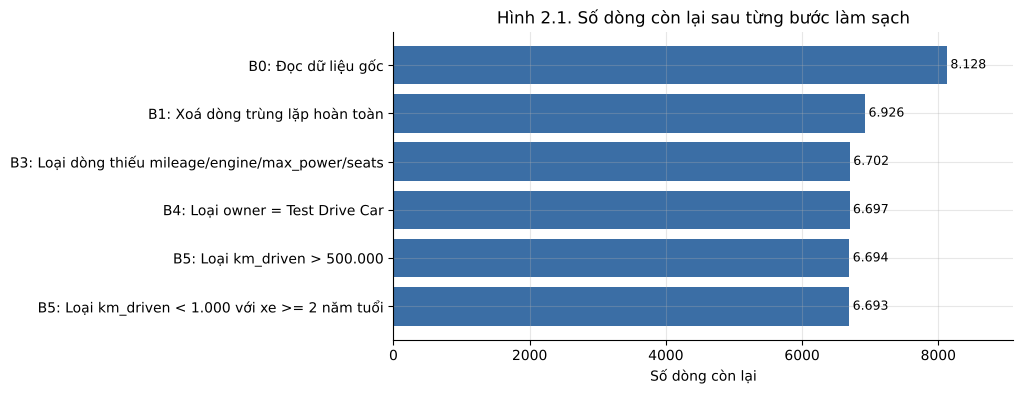

In [17]:
# Hình 2.1 — Số dòng còn lại sau từng bước
steps = log_df.drop_duplicates("so_dong_con_lai", keep="first")
fig, ax = plt.subplots(figsize=(8, 4))
labels = [f"B{r.buoc}: {r.noi_dung}" for r in steps.itertuples()]
ax.barh(labels[::-1], steps["so_dong_con_lai"][::-1], color="#3b6ea5")
for i, v in enumerate(steps["so_dong_con_lai"][::-1]):
    ax.text(v + 50, i, f"{v:,}".replace(",", "."), va="center", fontsize=9)
ax.set_xlabel("Số dòng còn lại")
ax.set_xlim(0, len(raw) * 1.12)
ax.set_title("Hình 2.1. Số dòng còn lại sau từng bước làm sạch")
fig.savefig(FIG_DIR / "hinh_2_1_so_dong_sau_tung_buoc.png")
plt.show()

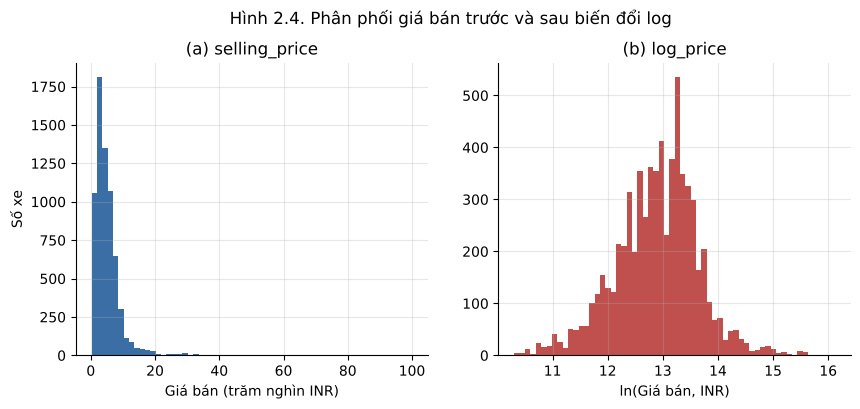

Độ lệch selling_price: 5.463 | Độ lệch log_price: -0.167


In [18]:
# Hình 2.4 — Phân phối giá bán: thang gốc và thang log
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
axes[0].hist(clean["selling_price"] / 1e5, bins=60, color="#3b6ea5")
axes[0].set_xlabel("Giá bán (trăm nghìn INR)")
axes[0].set_ylabel("Số xe")
axes[0].set_title("(a) selling_price")
axes[1].hist(clean["log_price"], bins=60, color="#c0504d")
axes[1].set_xlabel("ln(Giá bán, INR)")
axes[1].set_title("(b) log_price")
fig.suptitle("Hình 2.4. Phân phối giá bán trước và sau biến đổi log", y=1.02)
fig.savefig(FIG_DIR / "hinh_2_4_phan_phoi_gia_log.png")
plt.show()
print("Độ lệch selling_price:", round(clean["selling_price"].skew(), 3),
      "| Độ lệch log_price:", round(clean["log_price"].skew(), 3))

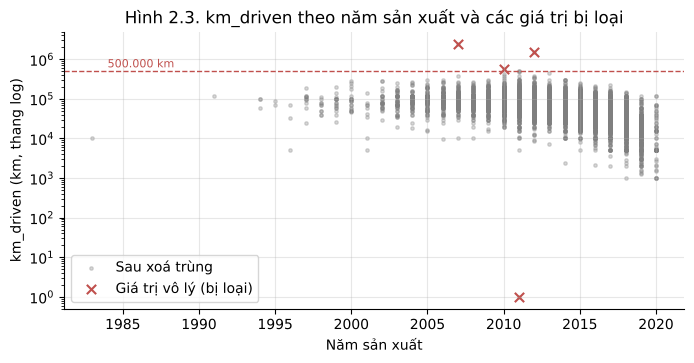

In [19]:
# Hình 2.3 — km_driven: các điểm bị loại
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.scatter(raw.loc[~dup_mask, "year"], raw.loc[~dup_mask, "km_driven"], s=6, alpha=0.3,
           color="#7f7f7f", label="Sau xoá trùng")
bad = raw.loc[~dup_mask & ((raw["km_driven"] > KM_MAX) |
                           ((raw["km_driven"] < KM_MIN) & (REFERENCE_YEAR - raw["year"] >= MIN_AGE_FOR_KM_MIN)))]
ax.scatter(bad["year"], bad["km_driven"], s=45, color="#c0504d", marker="x", label="Giá trị vô lý (bị loại)")
ax.axhline(KM_MAX, ls="--", color="#c0504d", lw=1)
ax.text(1984, KM_MAX * 1.25, "500.000 km", color="#c0504d", fontsize=8)
ax.set_yscale("log")
ax.set_ylim(0.5, 5e6)
ax.set_xlabel("Năm sản xuất")
ax.set_ylabel("km_driven (km, thang log)")
ax.set_title("Hình 2.3. km_driven theo năm sản xuất và các giá trị bị loại")
ax.legend(loc="lower left")
fig.savefig(FIG_DIR / "hinh_2_3_km_driven_vo_ly.png")
plt.show()

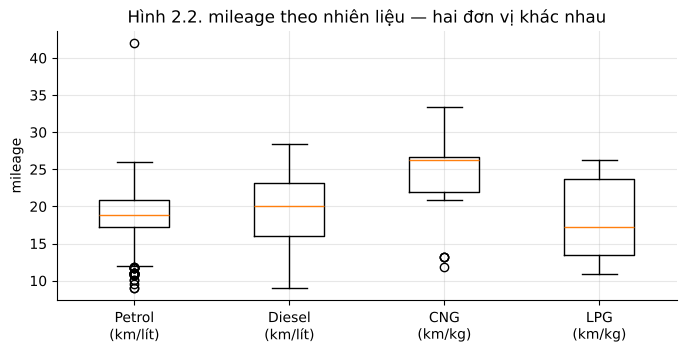

In [20]:
# Hình 2.2 — mileage theo đơn vị (không gộp chung)
fig, ax = plt.subplots(figsize=(8, 3.5))
data = [clean.loc[clean["fuel"] == f, "mileage"] for f in ["Petrol", "Diesel", "CNG", "LPG"]]
ax.boxplot(data, tick_labels=["Petrol\n(km/lít)", "Diesel\n(km/lít)", "CNG\n(km/kg)", "LPG\n(km/kg)"])
ax.set_ylabel("mileage")
ax.set_title("Hình 2.2. mileage theo nhiên liệu — hai đơn vị khác nhau")
fig.savefig(FIG_DIR / "hinh_2_2_mileage_theo_don_vi.png")
plt.show()

## Tóm tắt cho các thành viên khác

* Đọc file: `pd.read_csv("data/processed/cleaned_cars.csv")` (repo) — trên Kaggle tải file này lên làm Input.
* Biến phụ thuộc khuyến nghị: `log_price`. Diễn giải hệ số β của hồi quy log-tuyến tính: giá thay đổi
  $100(e^{\beta}-1)\%$.
* Nhiên liệu: dùng `fuel_group` (3 mức) cho kiểm định; `fuel` (4 mức) cho mô tả.
* `mileage` chỉ so sánh trong cùng `mileage_unit`.
* `owner_rank` dùng cho Spearman / kiểm định xu hướng.
* `torque_nm` là biến phụ (có vài ô NA), tránh đưa cùng `engine`, `max_power` vào mô hình;
  **không** gọi `dropna()` trên toàn bộ bảng nếu không dùng `torque_nm`.
* Mọi thay đổi sau mốc đóng băng v1.0 phải báo cả nhóm và tăng số phiên bản (v1.1, …).